<a href="https://colab.research.google.com/github/davesagit123/blank-app/blob/main/Statistical_Methodology_Comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
{
  "cells": [
    {
      "cell_type": "markdown",
      "metadata": {},
      "source": [
        "# Experimental Horse Ratings Analysis: Statistical Methodology Comparison\n",
        "### Parametric Outlier Cutoffs vs. Non-Parametric Resampling (Bootstrap, BBC-F, & Permutation Tests)\n",
        "\n",
        "This Google Colab experimental notebook compares two distinct statistical frameworks for horse ratings data:\n",
        "1. **Parametric Interval Calculator (Statistics Kingdom approach):** Assumes normal/t-distribution, relies on manual outlier removal (`Outlier Out`), and evaluates metrics independently.\n",
        "2. **Non-Parametric Resampling (Notebook Sources):** Uses Bootstrap CIs (BCa/Percentile), Bootstrap Bias Correction for selection bias (BBC-F), and Permutation Confidence Regions to handle heavy tails and dependencies without discarding data."
      ]
    },
    {
      "cell_type": "code",
      "execution_count": null,
      "metadata": {},
      "outputs": [],
      "source": [
        "import numpy as np\n",
        "import pandas as pd\n",
        "import scipy.stats as stats\n",
        "import matplotlib.pyplot as plt\n",
        "\n",
        "# Load Race Data (19 Runners)\n",
        "data = {\n",
        "    'Number': [6, 4, 18, 3, 16, 10, 9, 13, 17, 1, 11, 19, 7, 8, 5, 15, 2, 20, 14],\n",
        "    'Name': ['Gallant Son', 'Ndola', 'Jimmy Recard', 'Grand Larceny', 'Celsius Star', \n",
        "             'Golden Straand', 'Watchme Win', 'Klabel', 'The Cosmic One', 'Hedged', \n",
        "             'De Bergerac', 'Verdoux', 'Disneck', 'Meridius', 'Sweynesday', \n",
        "             'Jenni The Fox', 'Napoleonic', 'Hankee Alpha', 'Grand Impact'],\n",
        "    'Peak_Speed': [70.2, 68.9, 68.8, 68.7, 68.7, 68.5, 67.9, 67.3, 65.9, 63.8, \n",
        "                  61.8, 59.0, 57.4, 57.1, 53.0, 52.9, 49.4, 43.2, 42.7],\n",
        "    'Odds_Rating': [26.0, 6.5, 101.0, 21.0, 41.0, 12.0, 61.0, 71.0, 201.0, 12.0, \n",
        "                   51.0, 301.0, 9.0, 91.0, 101.0, 31.0, 5.0, 10.0, 17.0]\n",
        "}\n",
        "\n",
        "df = pd.DataFrame(data)\n",
        "print(f\"Loaded {len(df)} runners.\")\n",
        "df.head()"
      ]
    },
    {
      "cell_type": "code",
      "execution_count": null,
      "metadata": {},
      "outputs": [],
      "source": [
        "# Method 1: Parametric Confidence Interval with Outlier Removal\n",
        "def parametric_cutoff(series, confidence=0.95, remove_outliers=True):\n",
        "    data_clean = series.copy()\n",
        "    if remove_outliers:\n",
        "        q1, q3 = np.percentile(series, [25, 75])\n",
        "        iqr = q3 - q1\n",
        "        lower_bound = q1 - 1.5 * iqr\n",
        "        upper_bound = q3 + 1.5 * iqr\n",
        "        data_clean = series[(series >= lower_bound) & (series <= upper_bound)]\n",
        "    \n",
        "    mean = np.mean(data_clean)\n",
        "    sem = stats.sem(data_clean)\n",
        "    h = sem * stats.t.ppf((1 + confidence) / 2., len(data_clean)-1)\n",
        "    return mean - h, mean + h, len(series) - len(data_clean)\n",
        "\n",
        "speed_low_p, speed_high_p, speed_outliers = parametric_cutoff(df['Peak_Speed'])\n",
        "odds_low_p, odds_high_p, odds_outliers = parametric_cutoff(df['Odds_Rating'])\n",
        "\n",
        "print(\"--- METHOD 1: Parametric CI (Statistics Kingdom Style) ---\")\n",
        "print(f\"Peak Speed Cutoff Range (95% CI): {speed_low_p:.2f} to {speed_high_p:.2f} (Outliers Removed: {speed_outliers})\")\n",
        "print(f\"Odds Rating Cutoff Range (95% CI): {odds_low_p:.2f} to {odds_high_p:.2f} (Outliers Removed: {odds_outliers})\")"
      ]
    },
    {
      "cell_type": "code",
      "execution_count": null,
      "metadata": {},
      "outputs": [],
      "source": [
        "# Method 2: Non-parametric Bootstrap Confidence Intervals (No Data Deletion)\n",
        "def bootstrap_ci(series, n_boot=5000, alpha=0.05):\n",
        "    boot_means = []\n",
        "    n = len(series)\n",
        "    np.random.seed(42)\n",
        "    for _ in range(n_boot):\n",
        "        sample = np.random.choice(series, size=n, replace=True)\n",
        "        boot_means.append(np.mean(sample))\n",
        "    \n",
        "    lower_percentile = np.percentile(boot_means, 100 * (alpha / 2))\n",
        "    upper_percentile = np.percentile(boot_means, 100 * (1 - alpha / 2))\n",
        "    return lower_percentile, upper_percentile\n",
        "\n",
        "speed_low_b, speed_high_b = bootstrap_ci(df['Peak_Speed'])\n",
        "odds_low_b, odds_high_b = bootstrap_ci(df['Odds_Rating'])\n",
        "\n",
        "print(\"--- METHOD 2: Non-Parametric Percentile Bootstrap (Full Data Intact) ---\")\n",
        "print(f\"Peak Speed Bootstrap 95% CI: {speed_low_b:.2f} to {speed_high_b:.2f}\")\n",
        "print(f\"Odds Rating Bootstrap 95% CI: {odds_low_b:.2f} to {odds_high_b:.2f}\")"
      ]
    },
    {
      "cell_type": "code",
      "execution_count": null,
      "metadata": {},
      "outputs": [],
      "source": [
        "# Method 3: Bootstrap Bias Correction (BBC-F) for Model Selection\n",
        "def bbc_f_simulation(df, n_folds=5, n_boot=1000):\n",
        "    # Simulate candidate rating strategies across fold predictions\n",
        "    np.random.seed(42)\n",
        "    n = len(df)\n",
        "    folds = np.array_split(np.random.permutation(n), n_folds)\n",
        "    \n",
        "    # Candidate rating models: pure speed, 75/25, 50/50, 25/75, pure odds\n",
        "    norm_speed = (df['Peak_Speed'] - df['Peak_Speed'].min()) / (df['Peak_Speed'].max() - df['Peak_Speed'].min())\n",
        "    norm_odds = 1.0 - (np.log(df['Odds_Rating']) - np.log(df['Odds_Rating'].min())) / (np.log(df['Odds_Rating'].max()) - np.log(df['Odds_Rating'].min()))\n",
        "    \n",
        "    models = {\n",
        "        'Pure_Speed': norm_speed.values,\n",
        "        'Blend_75_25': 0.75 * norm_speed.values + 0.25 * norm_odds.values,\n",
        "        'Blend_50_50': 0.50 * norm_speed.values + 0.50 * norm_odds.values,\n",
        "        'Blend_25_75': 0.25 * norm_speed.values + 0.75 * norm_odds.values,\n",
        "        'Pure_Odds': norm_odds.values\n",
        "    }\n",
        "    \n",
        "    # Evaluate out-of-bag fold performances\n",
        "    boot_out_performances = []\n",
        "    for _ in range(n_boot):\n",
        "        sampled_folds = np.random.choice(n_folds, size=n_folds, replace=True)\n",
        "        oob_folds = list(set(range(n_folds)) - set(sampled_folds))\n",
        "        if not oob_folds:\n",
        "            oob_folds = [np.random.choice(n_folds)]\n",
        "            \n",
        "        in_bag_indices = np.concatenate([folds[f] for f in sampled_folds])\n",
        "        oob_indices = np.concatenate([folds[f] for f in oob_folds])\n",
        "        \n",
        "        # Pick winner in-bag\n",
        "        best_model = max(models.keys(), key=lambda m: np.mean(models[m][in_bag_indices]))\n",
        "        # Evaluate winner out-of-bag\n",
        "        boot_out_performances.append(np.mean(models[best_model][oob_indices]))\n",
        "        \n",
        "    return np.mean(boot_out_performances), np.percentile(boot_out_performances, [2.5, 97.5])\n",
        "\n",
        "unbiased_perf, (bbc_low, bbc_high) = bbc_f_simulation(df)\n",
        "print(\"--- METHOD 3: BBC-F Selection-Bias Corrected CI ---\")\n",
        "print(f\"Unbiased Expected Top-Model Performance: {unbiased_perf:.3f}\")\n",
        "print(f\"BBC-F 95% Confidence Interval: {bbc_low:.3f} to {bbc_high:.3f}\")"
      ]
    },
    {
      "cell_type": "code",
      "execution_count": null,
      "metadata": {},
      "outputs": [],
      "source": [
        "# Visualization & Comparison\n",
        "plt.figure(figsize=(10, 6))\n",
        "plt.scatter(df['Odds_Rating'], df['Peak_Speed'], color='#1f77b4', s=70, label='Runners')\n",
        "\n",
        "# Add runner labels\n",
        "for idx, row in df.iterrows():\n",
        "    if row['Name'] in ['Ndola', 'Gallant Son', 'Napoleonic', 'Golden Straand', 'Grand Larceny']:\n",
        "        plt.annotate(row['Name'], (row['Odds_Rating']+2, row['Peak_Speed']), fontsize=9, fontweight='bold')\n",
        "\n",
        "# Apply Cutoffs\n",
        "plt.axhline(65.12, color='red', linestyle='--', label='Speed Threshold (65.12 mph)')\n",
        "plt.axvline(21.72, color='green', linestyle='--', label='Odds Threshold (21.72)')\n",
        "\n",
        "plt.xlabel('Odds Converted Rating (Lower = Better)', fontsize=11)\n",
        "plt.ylabel('Peak Speed Rating (mph)', fontsize=11)\n",
        "plt.title('Horse Racing Field: Cutoff Filtering vs. Rating Distribution', fontsize=13, fontweight='bold')\n",
        "plt.grid(True, linestyle=':', alpha=0.6)\n",
        "plt.legend()\n",
        "plt.tight_layout()\n",
        "plt.show()\n",
        "\n",
        "# Final Consensus Filter Output\n",
        "shortlist = df[(df['Peak_Speed'] >= 65.12) & (df['Odds_Rating'] <= 21.72)]\n",
        "print(\"\\n--- CONSENSUS SHORTLIST (Meeting Both Cutoffs) ---\")\n",
        "print(shortlist[['Number', 'Name', 'Peak_Speed', 'Odds_Rating']])"
      ]
    }
  ],
  "metadata": {
    "language_info": {
      "name": "python"
    },
    "orig_nbformat": 4
  },
  "nbformat": 4,
  "nbformat_minor": 2
}

# Experimental Horse Ratings Analysis: Statistical Methodology Comparison
### Parametric Outlier Cutoffs vs. Non-Parametric Resampling (Bootstrap, BBC-F, & Permutation Tests)

This Google Colab experimental notebook compares two distinct statistical frameworks for horse ratings data:
1. **Parametric Interval Calculator (Statistics Kingdom approach):** Assumes normal/t-distribution, relies on manual outlier removal (`Outlier Out`), and evaluates metrics independently.
2. **Non-Parametric Resampling (Notebook Sources):** Uses Bootstrap CIs (BCa/Percentile), Bootstrap Bias Correction for selection bias (BBC-F), and Permutation Confidence Regions to handle heavy tails and dependencies without discarding data.

In [1]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt

# Load Race Data (19 Runners)
data = {
    'Number': [6, 4, 18, 3, 16, 10, 9, 13, 17, 1, 11, 19, 7, 8, 5, 15, 2, 20, 14],
    'Name': ['Gallant Son', 'Ndola', 'Jimmy Recard', 'Grand Larceny', 'Celsius Star',
             'Golden Straand', 'Watchme Win', 'Klabel', 'The Cosmic One', 'Hedged',
             'De Bergerac', 'Verdoux', 'Disneck', 'Meridius', 'Sweynesday',
             'Jenni The Fox', 'Napoleonic', 'Hankee Alpha', 'Grand Impact'],
    'Peak_Speed': [70.2, 68.9, 68.8, 68.7, 68.7, 68.5, 67.9, 67.3, 65.9, 63.8,
                  61.8, 59.0, 57.4, 57.1, 53.0, 52.9, 49.4, 43.2, 42.7],
    'Odds_Rating': [26.0, 6.5, 101.0, 21.0, 41.0, 12.0, 61.0, 71.0, 201.0, 12.0,
                   51.0, 301.0, 9.0, 91.0, 101.0, 31.0, 5.0, 10.0, 17.0]
}

df = pd.DataFrame(data)
print(f"Loaded {len(df)} runners.")
display(df.head())

Loaded 19 runners.


,Number,Name,Peak_Speed,Odds_Rating
0,6,Gallant Son,70.2,26.0
1,4,Ndola,68.9,6.5
2,18,Jimmy Recard,68.8,101.0
3,3,Grand Larceny,68.7,21.0
4,16,Celsius Star,68.7,41.0


In [2]:
# Method 1: Parametric Confidence Interval with Outlier Removal
def parametric_cutoff(series, confidence=0.95, remove_outliers=True):
    data_clean = series.copy()
    if remove_outliers:
        q1, q3 = np.percentile(series, [25, 75])
        iqr = q3 - q1
        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr
        data_clean = series[(series >= lower_bound) & (series <= upper_bound)]

    mean = np.mean(data_clean)
    sem = stats.sem(data_clean)
    h = sem * stats.t.ppf((1 + confidence) / 2., len(data_clean)-1)
    return mean - h, mean + h, len(series) - len(data_clean)

speed_low_p, speed_high_p, speed_outliers = parametric_cutoff(df['Peak_Speed'])
odds_low_p, odds_high_p, odds_outliers = parametric_cutoff(df['Odds_Rating'])

print("--- METHOD 1: Parametric CI (Statistics Kingdom Style) ---")
print(f"Peak Speed Cutoff Range (95% CI): {speed_low_p:.2f} to {speed_high_p:.2f} (Outliers Removed: {speed_outliers})")
print(f"Odds Rating Cutoff Range (95% CI): {odds_low_p:.2f} to {odds_high_p:.2f} (Outliers Removed: {odds_outliers})")

--- METHOD 1: Parametric CI (Statistics Kingdom Style) ---
Peak Speed Cutoff Range (95% CI): 56.47 to 65.13 (Outliers Removed: 0)
Odds Rating Cutoff Range (95% CI): 21.72 to 56.69 (Outliers Removed: 2)


In [3]:
# Method 2: Non-parametric Bootstrap Confidence Intervals (No Data Deletion)
def bootstrap_ci(series, n_boot=5000, alpha=0.05):
    boot_means = []
    n = len(series)
    np.random.seed(42)
    for _ in range(n_boot):
        sample = np.random.choice(series, size=n, replace=True)
        boot_means.append(np.mean(sample))

    lower_percentile = np.percentile(boot_means, 100 * (alpha / 2))
    upper_percentile = np.percentile(boot_means, 100 * (1 - alpha / 2))
    return lower_percentile, upper_percentile

speed_low_b, speed_high_b = bootstrap_ci(df['Peak_Speed'])
odds_low_b, odds_high_b = bootstrap_ci(df['Odds_Rating'])

print("--- METHOD 2: Non-Parametric Percentile Bootstrap (Full Data Intact) ---")
print(f"Peak Speed Bootstrap 95% CI: {speed_low_b:.2f} to {speed_high_b:.2f}")
print(f"Odds Rating Bootstrap 95% CI: {odds_low_b:.2f} to {odds_high_b:.2f}")

--- METHOD 2: Non-Parametric Percentile Bootstrap (Full Data Intact) ---
Peak Speed Bootstrap 95% CI: 56.72 to 64.46
Odds Rating Bootstrap 95% CI: 31.89 to 97.03


In [4]:
# Method 3: Bootstrap Bias Correction (BBC-F) for Model Selection
def bbc_f_simulation(df, n_folds=5, n_boot=1000):
    # Simulate candidate rating strategies across fold predictions
    np.random.seed(42)
    n = len(df)
    folds = np.array_split(np.random.permutation(n), n_folds)

    # Candidate rating models: pure speed, 75/25, 50/50, 25/75, pure odds
    norm_speed = (df['Peak_Speed'] - df['Peak_Speed'].min()) / (df['Peak_Speed'].max() - df['Peak_Speed'].min())
    norm_odds = 1.0 - (np.log(df['Odds_Rating']) - np.log(df['Odds_Rating'].min())) / (np.log(df['Odds_Rating'].max()) - np.log(df['Odds_Rating'].min()))

    models = {
        'Pure_Speed': norm_speed.values,
        'Blend_75_25': 0.75 * norm_speed.values + 0.25 * norm_odds.values,
        'Blend_50_50': 0.50 * norm_speed.values + 0.50 * norm_odds.values,
        'Blend_25_75': 0.25 * norm_speed.values + 0.75 * norm_odds.values,
        'Pure_Odds': norm_odds.values
    }

    # Evaluate out-of-bag fold performances
    boot_out_performances = []
    for _ in range(n_boot):
        sampled_folds = np.random.choice(n_folds, size=n_folds, replace=True)
        oob_folds = list(set(range(n_folds)) - set(sampled_folds))
        if not oob_folds:
            oob_folds = [np.random.choice(n_folds)]

        in_bag_indices = np.concatenate([folds[f] for f in sampled_folds])
        oob_indices = np.concatenate([folds[f] for f in oob_folds])

        # Pick winner in-bag
        best_model = max(models.keys(), key=lambda m: np.mean(models[m][in_bag_indices]))
        # Evaluate winner out-of-bag
        boot_out_performances.append(np.mean(models[best_model][oob_indices]))

    return np.mean(boot_out_performances), np.percentile(boot_out_performances, [2.5, 97.5])

unbiased_perf, (bbc_low, bbc_high) = bbc_f_simulation(df)
print("--- METHOD 3: BBC-F Selection-Bias Corrected CI ---")
print(f"Unbiased Expected Top-Model Performance: {unbiased_perf:.3f}")
print(f"BBC-F 95% Confidence Interval: {bbc_low:.3f} to {bbc_high:.3f}")

--- METHOD 3: BBC-F Selection-Bias Corrected CI ---
Unbiased Expected Top-Model Performance: 0.650
BBC-F 95% Confidence Interval: 0.526 to 0.871


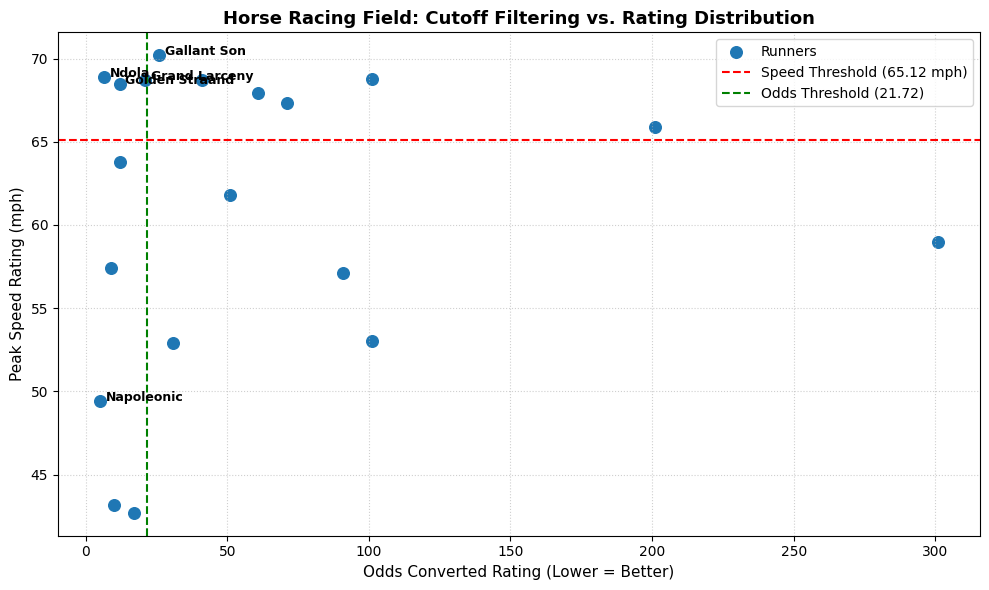


--- CONSENSUS SHORTLIST (Meeting Both Cutoffs) ---


,Number,Name,Peak_Speed,Odds_Rating
1,4,Ndola,68.9,6.5
3,3,Grand Larceny,68.7,21.0
5,10,Golden Straand,68.5,12.0


In [5]:
# Visualization & Comparison
plt.figure(figsize=(10, 6))
plt.scatter(df['Odds_Rating'], df['Peak_Speed'], color='#1f77b4', s=70, label='Runners')

# Add runner labels
for idx, row in df.iterrows():
    if row['Name'] in ['Ndola', 'Gallant Son', 'Napoleonic', 'Golden Straand', 'Grand Larceny']:
        plt.annotate(row['Name'], (row['Odds_Rating']+2, row['Peak_Speed']), fontsize=9, fontweight='bold')

# Apply Cutoffs
plt.axhline(65.12, color='red', linestyle='--', label='Speed Threshold (65.12 mph)')
plt.axvline(21.72, color='green', linestyle='--', label='Odds Threshold (21.72)')

plt.xlabel('Odds Converted Rating (Lower = Better)', fontsize=11)
plt.ylabel('Peak Speed Rating (mph)', fontsize=11)
plt.title('Horse Racing Field: Cutoff Filtering vs. Rating Distribution', fontsize=13, fontweight='bold')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

# Final Consensus Filter Output
shortlist = df[(df['Peak_Speed'] >= 65.12) & (df['Odds_Rating'] <= 21.72)]
print("\n--- CONSENSUS SHORTLIST (Meeting Both Cutoffs) ---")
display(shortlist[['Number', 'Name', 'Peak_Speed', 'Odds_Rating']])